In [1]:
import pandas as pd 

In [8]:
df = pd.read_csv("../data/hotel_bookings.csv")
pd.set_option("display.max_columns", None)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [9]:
df.shape

(119390, 32)

In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

### İlk Veri İncelemesi (Data Overview)

Veri seti **119.390 satır ve 32 sütundan** oluşmaktadır. İlk incelemede kolonların veri tipleri, benzersiz değer sayıları ve eksik veri oranları kontrol edilmiştir.

**Eksik Veri Analizi:**

- `company`: %94,31 (112.593 eksik)
- `agent`: %13,69 (16.340 eksik)
- `country`: %0,41 (488 eksik)
- `children`: %0,0034 (4 eksik)

**İlk Gözlemler:**
- Eksik değerler yalnızca 4 kolonda bulunmaktadır.
- `company` ve `agent` kolonlarındaki eksikliklerin rezervasyon türüyle ilişkili olup olmadığı araştırılmalıdır.
- `reservation_status_date` tarih bilgisi içermesine rağmen `str` veri tipindedir.
- Eksik değerlerin nasıl ele alınacağına karar vermeden önce kolonların iş anlamları incelenmelidir.

**Sonraki Adım:** Eksik değerlerin nedenlerini araştırmak ve uygun veri temizleme stratejisini belirlemek.

In [20]:
df.duplicated().sum()

np.int64(31994)

In [21]:
df[df.duplicated(keep=False)].head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
21,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,A,A,1,No Deposit,250.0,NaN,0,Transient,84.67,0,1,Check-Out,2015-07-07
39,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.0,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,0.0,0,HB,ROU,Direct,Direct,0,0,0,E,E,0,No Deposit,250.0,NaN,0,Transient,137.00,0,1,Check-Out,2015-07-07
132,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,240.0,NaN,0,Transient,97.00,0,0,Canceled,2015-07-01
198,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,109.80,0,3,Check-Out,2015-07-08


In [28]:
# aynı seyahat acentesi, aynı tarihte aynı otelde konaklayacak iki farklı 
# müşteri için aynı özelliklerde rezervasyon yapmış olabilir.
#Tekrarlanan satırlar iptal edilen rezervasyonlarda mı, yoksa iptal edilmeyen rezervasyonlarda mı daha yoğun?

duplicates = df[df.duplicated(keep=False)]

duplicates.value_counts('is_canceled')


is_canceled
1    23451
0    16714
Name: count, dtype: int64

In [33]:
# Veri setindeki tüm rezervasyonların yüzde kaçı iptal edilmiş?

pct = (df.value_counts('is_canceled'))/(len(df)) *100
print(pct)

is_canceled
0    62.958372
1    37.041628
Name: count, dtype: float64


In [35]:
drop_duplicated = df.drop_duplicates()

drop_pct = (drop_duplicated.value_counts("is_canceled")/len(drop)) * 100
print(drop_pct)

is_canceled
0    72.510184
1    27.489816
Name: count, dtype: float64


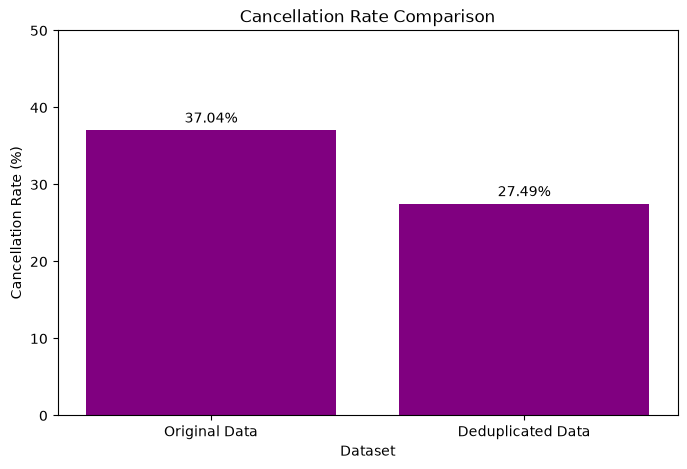

In [37]:
compare_df = pd.DataFrame({
    'dataset': ['Original Data', 'Deduplicated Data'],
    'cancel_rate': [37.04, 27.49]
})

import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(compare_df['dataset'], compare_df['cancel_rate'], color = "purple")
plt.title('Cancellation Rate Comparison')
plt.xlabel('Dataset')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 50)

for i, v in enumerate(compare_df['cancel_rate']):
    plt.text(i, v + 1, f'{v:.2f}%', ha='center')

plt.show()

### Duplicate Analysis (Tekrarlanan Kayıt Analizi)

Veri setindeki tekrar eden kayıtlar `duplicated()` yöntemiyle incelenmiştir.

**1. Duplicate Kontrolü**

- Toplam kayıt sayısı: **119.390**
- Tekrar eden kayıt sayısı: **31.994 (%26,80)**
- Tekrarsızlaştırılmış kayıt sayısı: **87.396**

`duplicated(keep=False)` kullanılarak ilk kayıtlar dahil tüm eşleşen satırlar incelenmiştir. Örneklerde varış tarihleri, konaklama süreleri, kişi sayıları, fiyatlar ve diğer rezervasyon özelliklerinin birebir aynı olduğu gözlemlenmiştir.

Ancak veri setinde benzersiz bir rezervasyon veya müşteri kimliği bulunmadığından, bu eşleşmelerin kesin olarak hatalı kayıtlar olduğu söylenemez.

**2. Duplicate Kayıtların İptal Durumuna Göre İncelenmesi**

Tekrar eden gruplarda toplam **40.165 kayıt** bulunmaktadır.

- İptal edilen: 23.451 (%58,39)
- İptal edilmeyen: 16.714 (%41,61)

Ayrıca iptal edilen tüm rezervasyonların yaklaşık **%53'ü**, birebir aynı özelliklere sahip başka kayıtların bulunduğu gruplarda yer almaktadır.

Bu durum, tekrar eden kayıtlarla iptal durumu arasında bir ilişki olabileceğini göstermektedir. Ancak bu ilişki, tekrarların neden oluştuğunu açıklamak için tek başına yeterli değildir.

**3. Duplicate Temizliğinin İptal Oranına Etkisi**

`drop_duplicates()` yöntemiyle oluşturulan geçici bir veri seti üzerinde iptal oranları yeniden hesaplanmıştır.

| Metrik | Orijinal Veri | Tekrarsızlaştırılmış Veri |
|---|---:|---:|
| Toplam kayıt | 119.390 | 87.396 |
| İptal oranı | %37,04 | %27,49 |

Duplicate satırların çıkarılmasıyla iptal oranı **9,55 yüzde puan azalmıştır.**

Bu farklılık, tekrar eden kayıtların kaldırılmasının temel performans göstergelerini (KPI) önemli ölçüde değiştirebildiğini göstermektedir.

**4. Değerlendirme ve Karar**

Tekrarlanan kayıtların önemli bir kısmı iptal edilmiş rezervasyonlardan oluşmaktadır. Bunun nedenleri arasında rezervasyonların sistemde birden fazla kez kaydedilmesi veya aynı özelliklere sahip farklı rezervasyonların bulunması gibi ihtimaller değerlendirilebilir.

Ancak bu hipotezler mevcut verilerle doğrulanamamıştır.

**Veri temizleme kararı:** Orijinal veri seti korunacaktır. Tekrarsızlaştırılmış veri seti karşılaştırma amacıyla kullanılacak, duplicate kayıtların kalıcı olarak kaldırılmasına henüz karar verilmeyecektir.

Olasılık A — Sistemsel tekrar
Aslında tek bir rezervasyon yapılmıştır ancak sistem aynı rezervasyonu yanlışlıkla iki kez kaydetmiştir.
Bu durumda gerçekten fazladan bir kayıt vardır ve temizlenmesi gerekebilir.
Olasılık B — İki farklı rezervasyon
İki farklı müşteri aynı otelde, aynı tarihlerde ve aynı koşullarda rezervasyon yapmış, ardından ikisi de rezervasyonunu iptal etmiş olabilir.

In [39]:
info = pd.DataFrame({
    'dtype': df.dtypes,
    'non_null': df.notnull().sum(),
    'null': df.isnull().sum(),
    'null_%': (df.isnull().mean() * 100).round(2),
    'unique': df.nunique()
})
info
# Tüm kolonların genel analizi

,dtype,non_null,null,null_%,unique
hotel,str,119390,0,0.00,2
is_canceled,int64,119390,0,0.00,2
lead_time,int64,119390,0,0.00,479
arrival_date_year,int64,119390,0,0.00,3
arrival_date_month,str,119390,0,0.00,12
arrival_date_week_number,int64,119390,0,0.00,53
arrival_date_day_of_month,int64,119390,0,0.00,31
stays_in_weekend_nights,int64,119390,0,0.00,17
stays_in_week_nights,int64,119390,0,0.00,35
adults,int64,119390,0,0.00,14
